# Further Zero Detection 
(after reading from 78 fluxes)\
Data: flux extraction logs for 4 media (reading/results/exchange_flux/...)\
Output: zero detection results with criteria (reading/results/exchange_flux/...)

In [1]:
import glob, os
import pandas as pd

RESULT_DIR = "/user/home/il22158/work/vEcoli/reading/results/exchange_flux"
THRESHOLD = 0.05

files = sorted(glob.glob(os.path.join(RESULT_DIR, "exchange_flux_summary_*_all.csv")))
df = pd.concat([pd.read_csv(f).assign(source_file=os.path.basename(f)) for f in files],
               ignore_index=True)

# valid reading = one row (variant, seed, metabolite) with data
valid = df[(df["n_timepoints"] > 0) & df["mean_flux"].notna()].copy()
valid["is_constant"] = valid["is_constant"].astype(bool)

stats = valid.groupby("metabolite")["is_constant"].agg(n_constant="sum", n_valid="size")
stats["frac_constant"] = stats["n_constant"] / stats["n_valid"]
stats = stats.sort_values("frac_constant", ascending=False)

zero_detected = stats.index[stats["frac_constant"] > THRESHOLD].tolist()
print(len(zero_detected), "metabolites constant in >5% of valid readings")
zero_detected

78 metabolites constant in >5% of valid readings


['5-Deoxy-D-Ribofuranose',
 'ASN',
 'BETAINE',
 'GLC',
 'GLY',
 'THR',
 'L-ALPHA-ALANINE',
 'L-ASPARTATE',
 'SUC',
 'GLYCEROL',
 'GLC-D-LACTONE',
 'CYTIDINE',
 'THYMINE',
 'Pi',
 'TUNGSTATE',
 'NITRATE',
 'CPD-10774',
 'CPD-108',
 'SER',
 'MI-PENTAKISPHOSPHATE',
 'CPD-183',
 'CYS',
 'AMMONIUM',
 'CPD-1772',
 'INDOLE',
 'S-ADENOSYL-4-METHYLTHIO-2-OXOBUTANOATE',
 'NA+',
 'BUTANAL',
 'ETOH',
 'GLN',
 'GLT',
 'CARBON-MONOXIDE',
 'FORMATE',
 'CPD-534',
 'FUM',
 'XANTHINE',
 'CPD-564',
 'LEU',
 'FE+3',
 'ARABINOSE',
 'GLYCOLALDEHYDE',
 'HIS',
 'D-LACTATE',
 'ILE',
 'CYTOSINE',
 'CPD-520',
 'VAL',
 'D-ALANINE',
 'TYR',
 'MET',
 'LYS',
 'URACIL',
 'PHE',
 'CPD-560',
 'CPD0-1958',
 'CA+2',
 'HYDROGEN-MOLECULE',
 'HYPOXANTHINE',
 '4FE-4S',
 'ACET',
 'S-ADENOSYLMETHIONINE',
 'MG+2',
 'SULFATE',
 'NITRITE',
 'UREA',
 'ARG',
 'CL-',
 'CH33ADO',
 'CPD-239',
 'GLYCOLLATE',
 'IMIDAZOLE-PYRUVATE',
 'PROTON',
 'MAL',
 'METOH',
 'K+',
 'PRO',
 'UNDECAPRENYL-DIPHOSPHATE',
 'TRP']

In [2]:
import re, glob
from collections import defaultdict

LOG_GLOB = "/user/home/il22158/work/slurm_logs/logs_save/exchange_flux_extract_462KO_basal_operon_on.*.out"
THRESHOLD = 0.05

n_samples = defaultdict(int)
n_constant = defaultdict(int)

for f in sorted(glob.glob(LOG_GLOB)):
    lines = open(f, errors="ignore").read().splitlines()
    start = next((i for i, l in enumerate(lines) if "n_samples" in l and "n_constant" in l), None)
    if start is None:
        print("no statistics table (skipped):", f)
        continue
    for l in lines[start + 2:]:          # skip header and 'metabolite' index line
        if l.startswith("=") or not l.strip():
            break
        m = re.match(r"^(.*?)\s+(\d+)\s+(\d+)\s+", l)
        if m:
            n_samples[m[1]] += int(m[2])
            n_constant[m[1]] += int(m[3])

frac = {k: n_constant[k] / n_samples[k] for k in n_samples}
zero_detected = sorted((k for k, v in frac.items() if v > THRESHOLD), key=lambda k: -frac[k])
print(len(n_samples), "metabolites;", len(zero_detected), "constant in >5% of samples")
for k in zero_detected:
    print(f"{frac[k]:.3f}  {k}  {n_constant[k]}/{n_samples[k]}")

no statistics table (skipped): /user/home/il22158/work/slurm_logs/logs_save/exchange_flux_extract_462KO_basal_operon_on.19608735.out
78 metabolites; 78 constant in >5% of samples
1.000  5-Deoxy-D-Ribofuranose  3018/3018
1.000  ASN  3018/3018
1.000  BETAINE  3018/3018
1.000  CYTIDINE  3018/3018
1.000  GLC  3018/3018
1.000  GLC-D-LACTONE  3018/3018
1.000  GLY  3018/3018
1.000  GLYCEROL  3018/3018
1.000  L-ALPHA-ALANINE  3018/3018
1.000  L-ASPARTATE  3018/3018
1.000  SUC  3018/3018
1.000  THR  3018/3018
1.000  Pi  3017/3018
1.000  THYMINE  3017/3018
0.998  NITRATE  3012/3018
0.998  TUNGSTATE  3012/3018
0.998  CPD-10774  3011/3018
0.998  CPD-108  3011/3018
0.997  SER  3010/3018
0.997  MI-PENTAKISPHOSPHATE  3009/3018
0.996  CPD-183  3005/3018
0.995  CYS  3002/3018
0.991  AMMONIUM  2990/3018
0.989  CPD-1772  2986/3018
0.989  INDOLE  2985/3018
0.979  S-ADENOSYL-4-METHYLTHIO-2-OXOBUTANOATE  2955/3018
0.974  NA+  2940/3018
0.970  BUTANAL  2928/3018
0.958  ETOH  2891/3018
0.955  GLN  2881/3018
0

In [3]:
import re, glob, csv
from collections import defaultdict

LOG = "/user/home/il22158/work/slurm_logs/logs_save/exchange_flux_extract_462KO_basal_operon_on.*.out"
OUT_DIR = "/user/home/il22158/work/vEcoli/reading/results/exchange_flux"
THRESHOLD = 0.99
CRITERION = "AND"   # "AND" = threshold exceeded in every medium, "OR" = in at least one

N = defaultdict(dict)   # N[metabolite][medium] = n_samples
C = defaultdict(dict)   # C[metabolite][medium] = n_constant
media = []

for f in sorted(glob.glob(LOG)):
    lines = open(f, errors="ignore").read().splitlines()
    i = next((k for k, l in enumerate(lines) if "n_samples" in l and "n_constant" in l), None)
    if i is None:      # log without a statistics table (e.g. failed no_ox task)
        continue
    suffix = next(l for l in lines if l.startswith("Output suffix:"))
    med = suffix.split("gene_knockout_462KO_")[-1].strip()
    media.append(med)
    for l in lines[i + 2:]:
        if l.startswith("=") or not l.strip():
            break
        m = re.match(r"^(.*?)\s+(\d+)\s+(\d+)\s+", l)
        if m:
            N[m[1]][med] = int(m[2])
            C[m[1]][med] = int(m[3])

rows = []
for k in N:
    n, c = sum(N[k].values()), sum(C[k].values())
    r = {"metabolite": k}
    for md in media:
        r[f"constant_{md}"] = f"{C[k][md]}/{N[k][md]}" if md in N[k] else ""
    r["constant_overall"] = f"{c}/{n}"
    r["_frac"] = c / n          # used only for sorting
    # flagged only if the threshold is exceeded in every medium
    if CRITERION == "AND":
        r["zero_detected"] = all(
            md in N[k] and C[k][md] / N[k][md] > THRESHOLD for md in media
        )
    elif CRITERION == "OR":
        r["zero_detected"] = any(
            md in N[k] and C[k][md] / N[k][md] > THRESHOLD for md in media
        )
    rows.append(r)

rows.sort(key=lambda r: -r["_frac"])
for r in rows:
    del r["_frac"]

OUT = f"{OUT_DIR}/zero_detect_{CRITERION}_threshold_{THRESHOLD}.csv"

with open(OUT, "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=list(rows[0]))
    w.writeheader()
    w.writerows(rows)

zero_detected = [r["metabolite"] for r in rows if r["zero_detected"]]
print(media, len(rows), len(zero_detected))

['with_aa', 'basal', 'acetate', 'succinate'] 78 20


# Correlation with growth rate

**Plan: SHAP analysis of exchange fluxes vs. growth rate (462 KO, 4 media)**

## 1. Goal
Find which exchange fluxes best explain growth rate across the gene-knockout simulations. Do this per medium (basal, acetate, succinate, with_aa) and pooled, using SHAP. Drop metabolites flagged `zero_detected == True` in `zero_detect_AND_threshold_0.99.csv` (78 rows), so constant fluxes are omitted.

## 2. Principle of the method
- **Model-based attribution rather than raw correlation.** Pearson or Spearman correlation gives one number per flux. It misses nonlinear effects and does not handle collinearity between fluxes. Instead, fit a flexible regressor (gradient boosting or random forest) `growth_rate = f(fluxes)`, then explain it with SHAP.
- **SHAP (Shapley values)** comes from cooperative game theory. Each feature's contribution to a prediction is its average marginal contribution over all feature orderings. It has three properties:
  - Local accuracy: `base value + Σ SHAP_i = prediction`.
  - Consistency.
  - Additivity.
  For decision trees and tree-based ensembles, `TreeExplainer` computes SHAP values efficiently without explicitly enumerating every possible subset. It traverses  tree paths and accounts for how the expected model output changes when a feature is treated as known versus unknown. 
- **How to read the output:**
  - Global importance is mean(|SHAP|) per flux.
  - The beeswarm plot shows the sign of SHAP against the flux value, which gives the direction of association (for example, higher uptake leading to higher growth). For each media condition, it plots out-of-fold (OOF) SHAP values from all five CV folds.
  - Dependence plots show nonlinear shape of how one feature’s contribution.
      - **X-axis:** The actual value of the selected feature for each data point in the dataset.
      - **Y-axis:** The corresponding **SHAP value** for that feature, showing how much that specific feature value increased or decreased the model's prediction relative to the baseline.
      - **Colour (Optional):** A second feature is often used to colour the dots, which helps reveal **feature interactions** (how the effect of the primary feature depends on the value of a second feature)
- **Caveats:**
  - SHAP explains the model, not causality. The knockout is the true cause, and the fluxes are co-outputs of the same metabolic state.
  - Correlated fluxes share credit, so I will cluster them and inspect.
  - Validate the model with cross-validated R² before trusting the SHAP values.

## 3. Data and unit of observation
- **Fluxes:** `results/exchange_flux/exchange_flux_summary_gene_knockout_462KO_{medium}_all.csv`. These are long format, with columns project, variant, label, lineage_seed, metabolite, mean_flux, median_flux and so on.
- **Growth:** `results/growth_rate/growth_rate_summary_gene_knockout_462KO_{medium}_all.csv`. The target is `mean_growth_rate`, one row per project/variant/lineage_seed.
- **Mask:** `zero_detect_AND_threshold_0.99.csv`, with columns `metabolite` and `zero_detected`.
- **Sample:** one (medium, variant/KO, lineage_seed) simulation. The join keys are `project, variant, lineage_seed`.
- **Scope:** only the `462KO` files are used. The `gene_ko_40trial` files in the same folder are excluded.

## 4. Steps
1. **Load and tag.** Load each medium and add a `medium` column.
2. **Normalizing.**
   - Match flux and growth samples on `project, variant, lineage_seed` and check for unmatched samples, duplicate keys and label mismatches.
   - Normalize within each medium with a robust z-score (median/MAD):
     - `flux_norm`: `mean_flux`, normalized per metabolite.
     - `growth_norm`: `mean_growth_rate`, normalized across samples.
   - Constant metabolites have zero MAD (median absolute deviation) and come out as NaN. They are removed in the next step.
   - Normalization does not change Spearman or tree-model results, which are rank-based or split-based. It matters for Pearson and for comparing media.
3. **Drop constant fluxes.**
   - Remove metabolites with `zero_detected == True`.
   - As a safety net, also drop any metabolite with `is_constant == True` or zero variance within the medium being analysed.
   - Report the counts removed.
4. **Pivot to wide.** Rows are samples and columns are metabolites, with `mean_flux` as the values. Optionally repeat with `median_flux` as a robustness check. Fill missing values with 0.
5. **Merge with growth.** Join on the keys above. Drop samples with no growth rate or with failed or short runs (check `n_timepoints` and `max_generation`).
6. **Baseline.** Compute the Spearman correlation of each flux with growth rate, as a reference for the SHAP ranking.
7. **Model.**
   - Use XGBoost (`XGBRegressor`, 400 trees, depth 4, learning rate 0.03).
   - Target is `growth_norm`, the robust z-score of `mean_growth_rate`. Features are the robust-z fluxes from the trimmed step 3.1 files.
   - Use 5-fold CV grouped by **variant (KO) label**, so lineage seeds of the same KO never fall in both train and test.
   - Report out-of-fold R² and RMSE per medium, and the mean and SD of fold R².
   - Fit one model per medium, plus a pooled model (union of metabolites, missing set to 0) with `medium` as a one-hot feature.
8. **SHAP.** SHAP values come from `TreeExplainer`, computed out-of-fold inside `run_cv`*` in previous step (where every sample is explained by a model that never saw it). The outputs are:
   - a bar plot of mean |SHAP| (top 20);
   - a beeswarm summary (fluxes clipped to the 1st–99th percentile for display, because robust-z values can be extreme);
   - dependence plots for the top 5 fluxes;
   - a CSV ranking of SHAP importance per medium, with each flux's Spearman correlation with the target.
9. **Compare media.**
   - Build a table and heatmap of each flux's share of total mean |SHAP|, for the top 25 fluxes.
   - Compute the rank correlation of importances between media.
   - List the top-10 fluxes shared by all media and those specific to one medium.
10. **Robustness.**
   - Repeat with 4 extra seeds in CV split, with log-transformed growth rate, and with `median_flux` (robust-z per metabolite). Compare the top-10 overlap and the rank correlation with the baseline.
   - `median_flux` is constant for many metabolites, so those drop out; expect weaker agreement there.
   - Cluster collinear fluxes (hierarchical clustering on 1 − |Spearman|, cut at 0.3) and report cluster-level SHAP, because credit is split arbitrarily within a cluster.

## 5. Outputs (to `reading/results/shap/`)
- `model_cv_metrics.csv`
- `shap_importance_{medium}.csv` and `shap_importance_pooled.csv`
- `shap_importance_share_by_medium.csv` and `shap_compare_media_heatmap.png`
- `shap_summary_{medium}.png`, `shap_bar_{medium}.png`, `shap_dependence_{medium}_*.png`
- `shap_robustness.csv` and `shap_clusters_{medium}.csv`
- A notebook `reading/shap_flux_growth.ipynb`, or a `.py` script (your choice)

## Coding

In [4]:
"""""
Step 1: Load, match and normalize exchange flux and growth rate data per medium.
"""""

from pathlib import Path
import numpy as np
import pandas as pd

RES = Path("/user/home/il22158/work/vEcoli/reading/results")
MEDIA = ["basal", "acetate", "succinate", "with_aa"]
KEYS = ["project", "variant", "lineage_seed"]


def robust_z(s):
    """Median/MAD z-score; falls back to NaN for constant series."""
    mad = (s - s.median()).abs().median() * 1.4826
    return (s - s.median()) / mad if mad > 0 else pd.Series(np.nan, index=s.index)


def load_matched(medium):
    flux = pd.read_csv(RES / f"exchange_flux/exchange_flux_summary_gene_knockout_462KO_{medium}_all.csv")
    growth = pd.read_csv(RES / f"growth_rate/growth_rate_summary_gene_knockout_462KO_{medium}_all.csv")
    fk = flux[KEYS + ["label"]].drop_duplicates()
    gk = growth[KEYS + ["label"]].drop_duplicates()
    m = fk.merge(gk, on=KEYS, how="outer", suffixes=("_flux", "_growth"), indicator=True)
    both = m[m["_merge"] == "both"]
    rep = {
        "medium": medium,
        "flux_samples": len(fk),
        "growth_samples": len(gk),
        "matched": len(both),
        "flux_only": int((m["_merge"] == "left_only").sum()),
        "growth_only": int((m["_merge"] == "right_only").sum()),
        "dup_growth_keys": int(growth.duplicated(KEYS).sum()),
        "label_mismatch": int((both["label_flux"] != both["label_growth"]).sum()),
        "n_KO": both["label_flux"].nunique(),
        "n_metabolites": flux["metabolite"].nunique(),
    }
    flux = flux.merge(both[KEYS], on=KEYS)
    growth = growth.merge(both[KEYS], on=KEYS)

    # Normalize within this medium only: flux per metabolite, growth across samples
    flux["flux_norm"] = flux.groupby("metabolite")["mean_flux"].transform(robust_z)
    growth["growth_norm"] = robust_z(growth["mean_growth_rate"])
    return flux, growth, rep


report = pd.DataFrame([load_matched(m)[2] for m in MEDIA]).set_index("medium")
print(report.to_string())

           flux_samples  growth_samples  matched  flux_only  growth_only  dup_growth_keys  label_mismatch  n_KO  n_metabolites
medium                                                                                                                        
basal               924             924      924          0            0                0               0   462             78
acetate             715             715      715          0            0                0               0   359             78
succinate           682             682      682          0            0                0               0   342             78
with_aa             697             697      697          0            0                0               0   349             78


In [5]:
"""""
Step 2: Drop constant fluxes and prepare wide-format data for each medium.
Uses the matched, normalized data from Step 1 (load_matched).
Criteria: drop metabolites flagged zero_detected, and any metabolite constant within a medium.
"""""
from pathlib import Path
import pandas as pd

RES = Path("/user/home/il22158/work/vEcoli/reading/results")
MEDIA = ["basal", "acetate", "succinate", "with_aa"]
KEYS = ["project", "variant", "lineage_seed"]

zero = pd.read_csv(RES / "exchange_flux/zero_detect_AND_threshold_0.99.csv")
print("zero_detect rows:", len(zero), "| zero_detected=True:", int(zero["zero_detected"].sum()))
drop_mets = set(zero.loc[zero["zero_detected"], "metabolite"])

wide, rows = {}, []
for m in MEDIA:
    flux, growth, _ = load_matched(m)
    all_mets = set(flux["metabolite"])

    # 1) drop constant fluxes flagged by the previous analysis
    flux = flux[~flux["metabolite"].isin(drop_mets)]

    # 2) long -> wide on the normalized flux
    X = (flux.pivot_table(index=KEYS + ["label"], columns="metabolite",
                          values="flux_norm", aggfunc="first").reset_index())

    # 3) attach the target (raw and normalized)
    df = X.merge(growth[KEYS + ["mean_growth_rate", "growth_norm"]], on=KEYS, how="inner")
    df.insert(0, "medium", m)

    # 4) safety net: drop anything still constant (or all-NaN) within this medium
    meta = KEYS + ["label", "medium", "mean_growth_rate", "growth_norm"]
    feat = [c for c in df.columns if c not in meta]
    const = [c for c in feat if df[c].isna().all() or df[c].nunique() <= 1]
    df = df.drop(columns=const)
    feat = [c for c in feat if c not in const]
    df[feat] = df[feat].fillna(0.0)

    n0 = len(df)
    df = df.dropna(subset=["growth_norm"])
    wide[m] = df
    rows.append({"medium": m, "metabolites_total": len(all_mets),
                 "dropped_zero_detect": len(all_mets & drop_mets),
                 "dropped_const_in_medium": len(const), "features_kept": len(feat),
                 "samples": len(df), "dropped_nan_growth": n0 - len(df),
                 "n_KO": df["label"].nunique(),
                 "flux_min": df[feat].min().min(), "flux_max": df[feat].max().max()})

print(pd.DataFrame(rows).set_index("medium").to_string())

out = RES / "shap"; out.mkdir(exist_ok=True)
for m, df in wide.items():
    df.to_csv(out / f"step2_features_{m}.csv", index=False)

zero_detect rows: 78 | zero_detected=True: 20
           metabolites_total  dropped_zero_detect  dropped_const_in_medium  features_kept  samples  dropped_nan_growth  n_KO    flux_min      flux_max
medium                                                                                                                                                
basal                     78                   20                        0             37      924                   0   462 -796.997334  5.505933e+04
acetate                   78                   20                        0             36      715                   0   359 -219.749837  1.591364e+21
succinate                 78                   20                        0             39      682                   0   342  -91.298534  5.306250e+14
with_aa                   78                   20                        0             32      697                   0   349 -610.524703  3.781115e+19


In [6]:

"""
Step 3: Compute Spearman correlation between exchange fluxes and growth rate for each medium.
"""
import pandas as pd
from scipy.stats import spearmanr

OUT = Path("/user/home/il22158/work/vEcoli/reading/results/shap")
MEDIA = ["basal", "acetate", "succinate", "with_aa"]
META = ["project", "variant", "lineage_seed", "label", "medium", "mean_growth_rate"]

res = []
for m in MEDIA:
    df = pd.read_csv(OUT / f"step2_features_{m}.csv")
    feats = [c for c in df.columns if c not in META]
    for f in feats:
        rho, p = spearmanr(df[f], df["mean_growth_rate"])
        res.append({"medium": m, "metabolite": f, "spearman_rho": rho, "p_value": p})

corr = pd.DataFrame(res)
corr["abs_rho"] = corr["spearman_rho"].abs()
corr = corr.sort_values(["medium", "abs_rho"], ascending=[True, False])
corr.to_csv(OUT / "step3_spearman_baseline.csv", index=False)

for m in MEDIA:
    print(f"\n== {m}: top 10 by |rho|")
    print(corr[corr.medium == m].head(10)[["metabolite", "spearman_rho", "p_value"]].to_string(index=False))

# Do media agree on which fluxes matter?
piv = corr.pivot(index="metabolite", columns="medium", values="spearman_rho")
print("\nRank correlation of rho between media:")
print(piv.corr(method="spearman").round(2).to_string())


== basal: top 10 by |rho|
              metabolite  spearman_rho       p_value
             growth_norm      1.000000  0.000000e+00
                     ARG     -0.975271  0.000000e+00
                     MAL     -0.965216  0.000000e+00
                  PROTON     -0.963220  0.000000e+00
                  4FE-4S     -0.950851  0.000000e+00
                     CL-     -0.879973 2.549901e-300
UNDECAPRENYL-DIPHOSPHATE     -0.873204 4.686558e-290
                     TRP     -0.833908 3.130504e-240
              GLYCOLLATE     -0.819022 1.140278e-224
                   METOH      0.813836 1.393959e-219

== acetate: top 10 by |rho|
              metabolite  spearman_rho       p_value
             growth_norm      1.000000  0.000000e+00
                     ARG     -0.988706  0.000000e+00
                     MAL     -0.983352  0.000000e+00
                   METOH      0.972355  0.000000e+00
                  PROTON     -0.966755  0.000000e+00
                  4FE-4S     -0.953497  0.0

In [7]:
"""
Step 3.1: Redo Spearman correlation excluding dead simulations
"""
from pathlib import Path
import pandas as pd
from scipy.stats import spearmanr

R = Path("/user/home/il22158/work/vEcoli/reading/results")
OUT = R / "shap"
MEDIA = ["basal", "acetate", "succinate", "with_aa"]
KEYS = ["project", "variant", "lineage_seed"]
META = KEYS + ["label", "medium", "mean_growth_rate"]

res, rep, trimmed = [], [], {}
for m in MEDIA:
    df = pd.read_csv(OUT / f"step2_features_{m}.csv")
    g = pd.read_csv(R / f"growth_rate/growth_rate_summary_gene_knockout_462KO_{m}_all.csv")
    df = df.merge(g[KEYS + ["n_timepoints", "duration_sec"]], on=KEYS)
    feats = [c for c in df.columns if c not in META + ["n_timepoints", "duration_sec"]]

    zero_growth = df["mean_growth_rate"] <= 0
    zero_flux = (df[feats] == 0).all(axis=1)
    rep.append({"medium": m, "n": len(df), "zero_growth": int(zero_growth.sum()),
                "all_zero_flux": int(zero_flux.sum()),
                "both": int((zero_growth & zero_flux).sum()),
                "zero_growth_only": int((zero_growth & ~zero_flux).sum()),
                "zero_flux_only": int((~zero_growth & zero_flux).sum())})

    # trim: drop non-growing and all-zero-flux simulations
    keep = df[~zero_growth & ~zero_flux].copy()
    # drop features that became constant after trimming
    feats = [f for f in feats if keep[f].nunique() > 1]
    trimmed[m] = keep
    for f in feats:
        rho, p = spearmanr(keep[f], keep["mean_growth_rate"])
        res.append({"medium": m, "metabolite": f, "spearman_rho": rho,
                    "p_value": p, "n_samples": len(keep)})

print(pd.DataFrame(rep).set_index("medium").to_string())

corr = pd.DataFrame(res)
corr["abs_rho"] = corr["spearman_rho"].abs()
corr = corr.sort_values(["medium", "abs_rho"], ascending=[True, False])
corr.to_csv(OUT / "step31_spearman_trimmed.csv", index=False)
for m, k in trimmed.items():
    k.to_csv(OUT / f"step31_trimmed_{m}.csv", index=False)

for m in MEDIA:
    c = corr[corr.medium == m]
    print(f"\n== {m} (n={c.n_samples.iloc[0]}): top 10 by |rho|")
    print(c.head(10)[["metabolite", "spearman_rho", "p_value"]].to_string(index=False))
    print("fluxes with |rho|>0.5:", int((c.abs_rho > 0.5).sum()), "of", len(c))

piv = corr.pivot(index="metabolite", columns="medium", values="spearman_rho")
print("\nRank correlation of rho between media:")
print(piv.corr(method="spearman").round(2).to_string())
old = pd.read_csv(OUT / "step3_spearman_baseline.csv")
print("\nMedian |rho| before vs after trim:")
print(pd.DataFrame({"before": old.groupby("medium").abs_rho.median(),
                    "after": corr.groupby("medium").abs_rho.median()}).round(2).to_string())

             n  zero_growth  all_zero_flux  both  zero_growth_only  zero_flux_only
medium                                                                            
basal      924          112              0     0               112               0
acetate    715           72              0     0                72               0
succinate  682           62              0     0                62               0
with_aa    697           72              0     0                72               0

== basal (n=812): top 10 by |rho|
              metabolite  spearman_rho       p_value
             growth_norm      1.000000  0.000000e+00
                     ARG     -0.963627  0.000000e+00
                     MAL     -0.948837  0.000000e+00
                  PROTON     -0.945901  0.000000e+00
                  4FE-4S     -0.931235  0.000000e+00
                     CL-     -0.824592 1.391969e-202
UNDECAPRENYL-DIPHOSPHATE     -0.813801 4.036872e-193
                     TRP     -0.757316 4.71

In [8]:
# %% Step 4: setup, data and CV helper
"""""
Step 4: Gradient-boosting model of growth_norm from exchange fluxes, with
out-of-fold SHAP. Input: step31_trimmed_{medium}.csv (matched, robust-z, trimmed).
CV is grouped by KO label so lineage seeds of one KO never span train and test.
"""""
from pathlib import Path
import numpy as np
import pandas as pd
import xgboost as xgb
import shap
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score, mean_squared_error

RES = Path("/user/home/il22158/work/vEcoli/reading/results")
OUT = RES / "shap"
MEDIA = ["basal", "acetate", "succinate", "with_aa"]
KEYS = ["project", "variant", "lineage_seed"]
META = ["medium", "project", "variant", "lineage_seed", "label",
        "mean_growth_rate", "growth_norm", "n_timepoints", "duration_sec"]
TARGET = "growth_norm"
SEEDS = [0, 1, 2, 3, 4]

data = {m: pd.read_csv(OUT / f"step31_trimmed_{m}.csv") for m in MEDIA}
feats = {m: [c for c in data[m].columns if c not in META] for m in MEDIA}

# Pooled: union of metabolites (missing -> 0) plus medium one-hot
pooled = pd.concat(data.values(), ignore_index=True)
pool_feat = sorted(set().union(*feats.values()))
pooled[pool_feat] = pooled[pool_feat].fillna(0.0)
for m in MEDIA:
    pooled[f"medium_{m}"] = (pooled["medium"] == m).astype(int)
pool_feat += [f"medium_{m}" for m in MEDIA]
data["pooled"], feats["pooled"] = pooled, pool_feat
RUNS = MEDIA + ["pooled"]


def make_model(seed):
    return xgb.XGBRegressor(n_estimators=400, learning_rate=0.03, max_depth=4,
                            subsample=0.8, colsample_bytree=0.8, min_child_weight=3,
                            reg_lambda=1.0, n_jobs=8, random_state=seed)


def run_cv(df, feat, target=TARGET, seed=0, n_splits=5, shuffle_groups=False):
    """Grouped K-fold by KO. Returns OOF predictions, OOF SHAP and fold metrics.
    shuffle_groups=True assigns whole KOs to folds at random (seeded)."""
    X, y, g = df[feat], df[target].to_numpy(), df["label"]
    if shuffle_groups:
        labels = g.unique()
        rng = np.random.default_rng(seed)
        fold_of = dict(zip(rng.permutation(labels), np.arange(len(labels)) % n_splits))
        fold = g.map(fold_of).to_numpy()
        splits = [(np.where(fold != k)[0], np.where(fold == k)[0]) for k in range(n_splits)]
    else:
        splits = GroupKFold(n_splits=n_splits).split(X, y, g)
    oof = np.zeros(len(df))
    sv = pd.DataFrame(0.0, index=df.index, columns=feat)
    fold_r2 = []
    for tr, te in splits:
        mdl = make_model(seed).fit(X.iloc[tr], y[tr])
        oof[te] = mdl.predict(X.iloc[te])
        sv.iloc[te] = shap.TreeExplainer(mdl).shap_values(X.iloc[te])
        fold_r2.append(r2_score(y[te], oof[te]))
    return oof, sv, {"r2_oof": r2_score(y, oof),
                     "rmse_oof": float(np.sqrt(mean_squared_error(y, oof))),
                     "r2_fold_mean": float(np.mean(fold_r2)),
                     "r2_fold_sd": float(np.std(fold_r2))}
    
# %% Step 4: fit per medium + pooled, save CV metrics
results, metrics = {}, []
for r in RUNS:
    oof, sv, met = run_cv(data[r], feats[r], seed=0)
    results[r] = {"oof": oof, "shap": sv}
    metrics.append({"run": r, "n_samples": len(data[r]), "n_KO": data[r]["label"].nunique(),
                    "n_features": len(feats[r]), **met})
metrics = pd.DataFrame(metrics).set_index("run")
metrics.to_csv(OUT / "model_cv_metrics.csv")
print(metrics.round(3).to_string())

           n_samples  n_KO  n_features  r2_oof  rmse_oof  r2_fold_mean  r2_fold_sd
run                                                                               
basal            812   406          37   0.994     0.294         0.994       0.004
acetate          643   323          36   0.999     0.056         0.999       0.001
succinate        620   311          39   0.998     0.135         0.998       0.001
with_aa          625   313          32   0.995     0.088         0.996       0.002
pooled          2700   406          45   0.996     0.188         0.996       0.002


In [9]:
"""
Step 5: Run SHAP analysis and generate plots for feature importance, summary, and dependence.
"""
# %% Step 5: SHAP importance, bar, beeswarm, dependence
def clip_for_display(X):
    """Flux outliers (up to ~1e20 after robust z) wreck colour scales; clip to 1-99%."""
    return X.clip(X.quantile(0.01), X.quantile(0.99), axis=1)


imp = {}
for r in RUNS:
    sv, X = results[r]["shap"], data[r][feats[r]]
    s = sv.abs().mean().sort_values(ascending=False)
    imp[r] = s
    pd.DataFrame({"metabolite": s.index, "mean_abs_shap": s.values,
                  "share": s.values / s.sum(),
                  "spearman_with_target": [spearmanr(X[c], data[r][TARGET])[0] for c in s.index]}
                 ).to_csv(OUT / f"shap_importance_{r}.csv", index=False)

    top = s.head(20)[::-1]
    plt.figure(figsize=(6, 6)); plt.barh(top.index, top.values)
    plt.xlabel("mean |SHAP|"); plt.title(f"{r}: top 20 fluxes"); plt.tight_layout()
    plt.savefig(OUT / f"shap_bar_{r}.png", dpi=150); plt.close()

    Xd = clip_for_display(X)
    shap.summary_plot(sv.values, Xd, max_display=20, show=False)
    plt.title(r); plt.tight_layout()
    plt.savefig(OUT / f"shap_summary_{r}.png", dpi=150); plt.close()

    top5 = list(s.index[:5])
    ymax = sv[top5].abs().to_numpy().max() * 1.05

    fig, axes = plt.subplots(1, 5, figsize=(11.69, 3.2), sharey=True)  # A4 landscape width
    for ax, c in zip(axes, top5):
        shap.dependence_plot(c, sv.values, Xd, interaction_index=None,
                             ax=ax, show=False, alpha=0.5, dot_size=8)
        # ax.set_title(c, fontsize=9)
        ax.set_ylim(-ymax, ymax)
        ax.set_ylabel("SHAP value" if ax is axes[0] else "")
    # fig.suptitle(f"{r}: SHAP dependence (top 5 fluxes)")
    fig.tight_layout()
    fig.savefig(OUT / f"shap_dependence_{r}.png", dpi=300); plt.close(fig)

imp = pd.DataFrame(imp)
for r in RUNS:
    print(f"\n{r} top 8:\n", imp[r].sort_values(ascending=False).head(8).round(4).to_string())



basal top 8:
 4FE-4S                      0.6813
CL-                         0.5638
PROTON                      0.3981
ARG                         0.3615
MAL                         0.2465
CA+2                        0.2236
TRP                         0.1333
UNDECAPRENYL-DIPHOSPHATE    0.1261

acetate top 8:
 ARG                         1.0085
PROTON                      0.2723
CL-                         0.1349
MAL                         0.1280
UNDECAPRENYL-DIPHOSPHATE    0.0646
4FE-4S                      0.0295
TRP                         0.0228
METOH                       0.0123

succinate top 8:
 4FE-4S                      0.9684
ARG                         0.7545
PROTON                      0.4331
MAL                         0.1834
UNDECAPRENYL-DIPHOSPHATE    0.1249
CL-                         0.0739
METOH                       0.0718
TRP                         0.0249

with_aa top 8:
 4FE-4S                      0.1700
UNDECAPRENYL-DIPHOSPHATE    0.1159
PROTON                

In [10]:

"""
Step 6: Compare SHAP importance across different media.
"""
# %% Step 6: compare media
share = (imp[MEDIA] / imp[MEDIA].sum()).fillna(0)
rank_corr = share.corr(method="spearman")
print("Spearman of importance shares between media:\n", rank_corr.round(2).to_string())

TOPK = 10
top_sets = {m: set(share[m].nlargest(TOPK).index) for m in MEDIA}
specific = {m: sorted(top_sets[m] - set().union(*[top_sets[o] for o in MEDIA if o != m]))
            for m in MEDIA}
shared = sorted(set.intersection(*top_sets.values()))
print("\nTop-10 in all media:", shared)
for m in MEDIA:
    print(f"Top-10 only in {m}:", specific[m])

keep = share.loc[share.max(axis=1).sort_values(ascending=False).index[:25]]
fig, ax = plt.subplots(figsize=(8, 9))
im = ax.imshow(keep.values, aspect="auto", cmap="viridis")
ax.set_xticks(range(len(MEDIA)), MEDIA, rotation=45, ha="right")
ax.set_yticks(range(len(keep)), keep.index)
fig.colorbar(im, ax=ax, label="share of total mean |SHAP|", pad=0.03)
fig.tight_layout()
fig.savefig(OUT / "shap_compare_media_heatmap.png",
            dpi=150, bbox_inches="tight", pad_inches=0.15)
plt.close(fig)
share.to_csv(OUT / "shap_importance_share_by_medium.csv")


Spearman of importance shares between media:
            basal  acetate  succinate  with_aa
basal       1.00     0.90       0.83     0.78
acetate     0.90     1.00       0.92     0.72
succinate   0.83     0.92       1.00     0.61
with_aa     0.78     0.72       0.61     1.00

Top-10 in all media: ['4FE-4S', 'CL-', 'MAL', 'PROTON', 'TRP', 'UNDECAPRENYL-DIPHOSPHATE']
Top-10 only in basal: ['CPD-560']
Top-10 only in acetate: []
Top-10 only in succinate: ['MET']
Top-10 only in with_aa: ['ACET']


In [11]:
"""
Step 7: Assess robustness of SHAP importance to different CV seeds, median flux, and log-transformed growth.
Also, cluster collinear fluxes and report cluster-level SHAP importance.
"""
from sklearn.model_selection import GroupKFold
from sklearn.utils import shuffle

# %% Step 7: robustness (seeds, median_flux, log growth) + collinearity clusters
def robust_z(s):
    mad = (s - s.median()).abs().median() * 1.4826
    return (s - s.median()) / mad if mad > 0 else s * np.nan


def median_flux_frame(m):
    f = pd.read_csv(RES / f"exchange_flux/exchange_flux_summary_gene_knockout_462KO_{m}_all.csv")
    f = f[f["metabolite"].isin(feats[m])].copy()
    f["z"] = f.groupby("metabolite")["median_flux"].transform(robust_z)
    X = f.pivot_table(index=KEYS, columns="metabolite", values="z", aggfunc="first")
    X = X.dropna(axis=1, how="all")   # median_flux is often constant (MAD=0) -> all NaN
    df = data[m][KEYS + ["label", TARGET]].merge(X.reset_index(), on=KEYS)
    cols = list(X.columns)
    df[cols] = df[cols].fillna(0.0)
    return df, cols


def top_overlap(a, b, k=TOPK):
    return len(set(a.nlargest(k).index) & set(b.nlargest(k).index)) / k


def run_cv(df, feat, target=TARGET, seed=0, n_splits=5, shuffle_groups=False):
    X, y, g = df[feat], df[target].to_numpy(), df["label"]
    if shuffle_groups:
        labels = g.unique()
        rng = np.random.default_rng(seed)
        fold_of = dict(zip(rng.permutation(labels), np.arange(len(labels)) % n_splits))
        fold = g.map(fold_of).to_numpy()
        splits = [(np.where(fold != k)[0], np.where(fold == k)[0]) for k in range(n_splits)]
    else:
        splits = GroupKFold(n_splits=n_splits).split(X, y, g)
    oof = np.zeros(len(df))
    sv = pd.DataFrame(0.0, index=df.index, columns=feat)
    fold_r2 = []
    for tr, te in splits:
        mdl = make_model(seed).fit(X.iloc[tr], y[tr])
        oof[te] = mdl.predict(X.iloc[te])
        sv.iloc[te] = shap.TreeExplainer(mdl).shap_values(X.iloc[te])
        fold_r2.append(r2_score(y[te], oof[te]))
    return oof, sv, {"r2_oof": r2_score(y, oof),
                     "rmse_oof": float(np.sqrt(mean_squared_error(y, oof))),
                     "r2_fold_mean": float(np.mean(fold_r2)),
                     "r2_fold_sd": float(np.std(fold_r2))}
    
rob = []
for m in MEDIA:
    base = imp[m].dropna()
    df = data[m]
    seed_imps = []
    for s in SEEDS[1:]:
            _, sv, met = run_cv(df, feats[m], seed=s, shuffle_groups=True)
            si = sv.abs().mean()
            rob.append({"medium": m, "variant": f"seed{s}", "r2": met["r2_oof"],
                        "rho_vs_base": spearmanr(base, si.reindex(base.index))[0],
                        "top10_overlap": top_overlap(base, si)})
    dfl = df.copy()
    g = dfl["mean_growth_rate"]
    dfl["growth_log"] = robust_z(np.log(g.clip(lower=g[g > 0].min())))
    _, sv, met = run_cv(dfl, feats[m], target="growth_log")
    si = sv.abs().mean()
    rob.append({"medium": m, "variant": "log_growth", "r2": met["r2_oof"],
                "rho_vs_base": spearmanr(base, si.reindex(base.index).fillna(0))[0],
                "top10_overlap": top_overlap(base, si)})

    dfm, mcols = median_flux_frame(m)
    _, sv, met = run_cv(dfm, mcols)
    si = sv.abs().mean()
    rob.append({"medium": m, "variant": "median_flux", "r2": met["r2_oof"],
                "rho_vs_base": spearmanr(base, si.reindex(base.index).fillna(0))[0],
                "top10_overlap": top_overlap(base, si)})
rob = pd.DataFrame(rob)
rob.to_csv(OUT / "shap_robustness.csv", index=False)
print(rob.round(3).to_string(index=False))

# Cluster collinear fluxes (|Spearman| > 0.7) and report cluster-level SHAP
for m in MEDIA:
    rho = data[m][feats[m]].corr(method="spearman").abs().fillna(0).to_numpy()
    d = 1 - rho
    np.fill_diagonal(d, 0)
    cl = fcluster(linkage(squareform(d, checks=False), "average"), t=0.3, criterion="distance")
    sv = results[m]["shap"]
    rows = []
    for k in np.unique(cl):
        mem = [f for f, c in zip(feats[m], cl) if c == k]
        rows.append({"cluster": k, "n": len(mem), "members": ";".join(mem),
                     "mean_abs_shap_sum": sv[mem].sum(axis=1).abs().mean()})
    cdf = pd.DataFrame(rows).sort_values("mean_abs_shap_sum", ascending=False)
    cdf.to_csv(OUT / f"shap_clusters_{m}.csv", index=False)
    print(f"\n{m}: top clusters\n", cdf.head(4)[["n", "mean_abs_shap_sum", "members"]]
          .assign(members=lambda x: x.members.str.slice(0, 60)).round(3).to_string(index=False))


   medium     variant    r2  rho_vs_base  top10_overlap
    basal       seed1 0.995        0.978            1.0
    basal       seed2 0.994        0.919            0.9
    basal       seed3 0.994        0.934            0.9
    basal       seed4 0.990        0.946            0.9
    basal  log_growth 0.985        0.940            0.9
    basal median_flux 0.971        0.564            0.6
  acetate       seed1 0.999        0.976            1.0
  acetate       seed2 0.999        0.983            0.9
  acetate       seed3 0.999        0.983            0.9
  acetate       seed4 0.999        0.984            0.9
  acetate  log_growth 0.973        0.822            0.9
  acetate median_flux 0.997        0.653            0.8
succinate       seed1 0.998        0.978            1.0
succinate       seed2 0.998        0.969            0.9
succinate       seed3 0.998        0.964            0.9
succinate       seed4 0.998        0.983            0.9
succinate  log_growth 0.983        0.886        

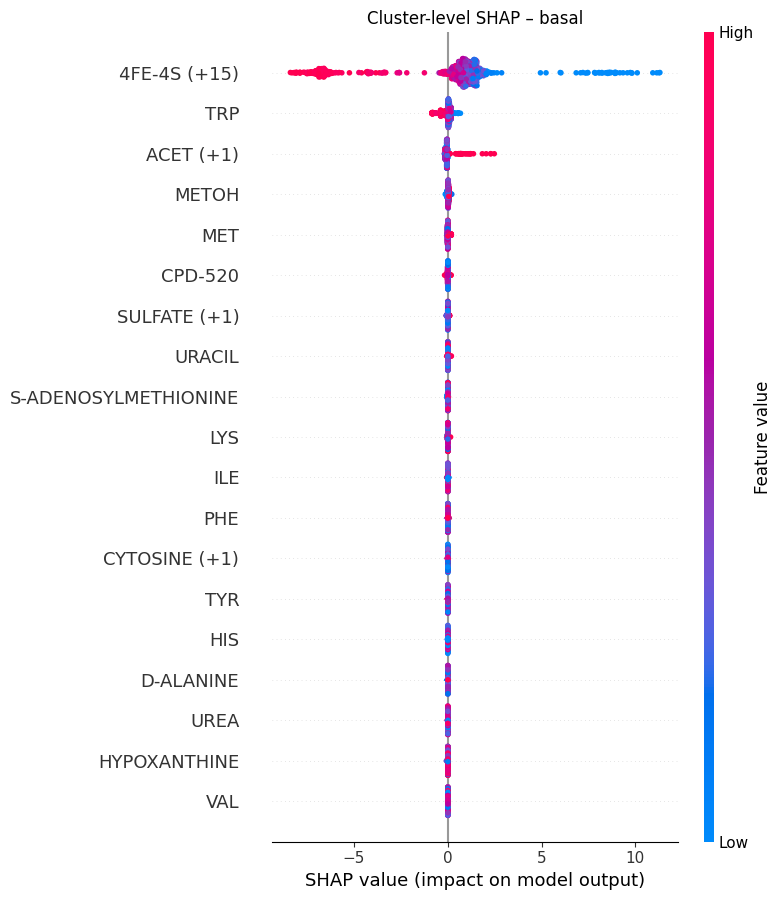

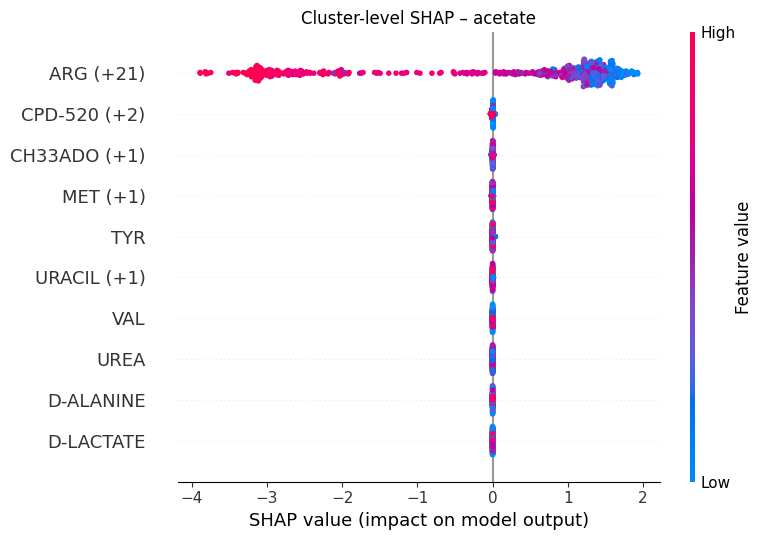

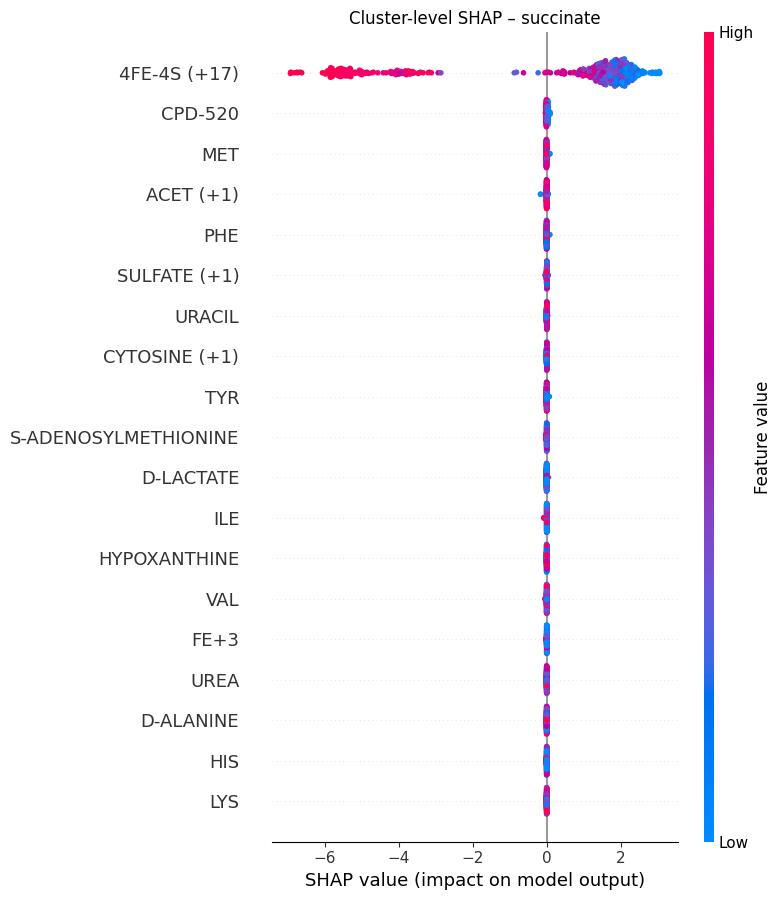

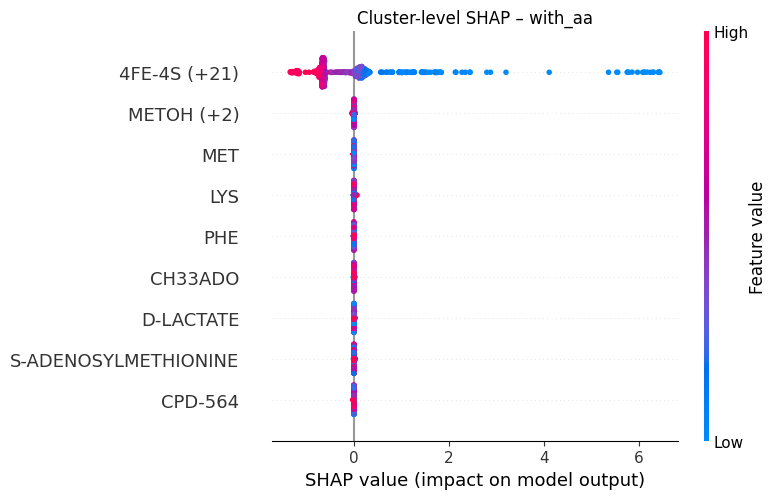

In [12]:
# %% Step 7b: cluster-level SHAP summary plots (same format as shap_summary_{medium}.png)
import matplotlib.pyplot as plt

MAX_DISPLAY = 20   # change to match the original summary plots

for m in MEDIA:
    # Rebuild the same clusters as Step 7
    rho = data[m][feats[m]].corr(method="spearman").abs().fillna(0).to_numpy()
    d = 1 - rho
    np.fill_diagonal(d, 0)
    cl = fcluster(linkage(squareform(d, checks=False), "average"), t=0.3, criterion="distance")

    sv = results[m]["shap"]                       # samples x features
    Xf = data[m][feats[m]].loc[sv.index]
    Xr = Xf.rank(pct=True)                        # rank-normalise so members share one colour scale

    csv_, cX, names = {}, {}, []
    for k in np.unique(cl):
        mem = [f for f, c in zip(feats[m], cl) if c == k]
        top = sv[mem].abs().mean().idxmax()       # label = most important member (+ n-1 others)
        name = top if len(mem) == 1 else f"{top} (+{len(mem) - 1})"
        csv_[name] = sv[mem].sum(axis=1)          # cluster SHAP = sum of member SHAP
        cX[name] = Xr[mem].mean(axis=1)           # cluster feature value = mean member rank
        names.append(name)

    csv_ = pd.DataFrame(csv_)[names]
    cX = pd.DataFrame(cX)[names]

    plt.figure()
    shap.summary_plot(csv_.to_numpy(), cX, feature_names=names,
                      max_display=MAX_DISPLAY, show=False)
    plt.title(f"Cluster-level SHAP – {m}")
    plt.tight_layout()
    plt.savefig(OUT / f"shap_cluster_summary_{m}.png", dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()

## 6. Results

**Data flow.** See `reading/shap_flux_growth_flow.mmd`. Flux and growth samples match completely in all four media (924 / 715 / 682 / 697). After removing constant fluxes and single-timepoint runs (`n_timepoints` = 1), 812 / 643 / 620 / 625 samples remain, covering 406 / 323 / 311 / 313 KOs and 37 / 36 / 39 / 32 fluxes (basal / acetate / succinate / with_aa).

**Single-flux association (`step31_spearman_trimmed.csv`).** Many fluxes already track growth closely (|ρ| ≈ 0.9–0.99 for the top four per medium). Nearly all are negative, with METOH (acetate, succinate) and CPD0-1958 (with_aa) as positive exceptions.

**Prediction (`model_cv_metrics.csv`).** Exchange fluxes predict growth of KOs the model has not seen with out-of-fold R² of 0.994 (basal), 0.999 (acetate), 0.998 (succinate), 0.995 (with_aa) and 0.996 (pooled).

**Key fluxes (`shap_importance_*.csv`).**
- **Basal:** 4FE-4S (0.68), CL- (0.56), PROTON (0.40), ARG (0.36).
- **Acetate:** ARG (1.01, 59% of the total), PROTON (0.27).
- **Succinate:** 4FE-4S (0.97), ARG (0.75), PROTON (0.43).
- **With_aa:** more evenly spread, led by 4FE-4S (0.17), UNDECAPRENYL-DIPHOSPHATE (0.12) and PROTON (0.11).
- **Pooled:** UNDECAPRENYL-DIPHOSPHATE (0.71), ARG (0.57), PROTON (0.31).

**Across media (`shap_importance_share_by_medium.csv`).** Importance rankings agree between media (rank correlation 0.61–0.92). Six fluxes are in the top 10 of every medium: 4FE-4S, CL-, MAL, PROTON, TRP and UNDECAPRENYL-DIPHOSPHATE. Medium-specific signals are CPD-560 (basal), MET (succinate) and ACET (with_aa).

**Stability (`shap_robustness.csv`).**
- **Seeds and shuffled KO folds:** R² 0.989–0.999, rank correlation 0.92–0.98 and top-10 overlap 0.9–1.0.
- **Log growth:** top-10 overlap 0.8–0.9.
- **Median flux:** a more moderate agreement (rank correlation 0.34–0.65, top-10 overlap 0.4–0.8), which suggests the mean captures information in high-flux time points.

**Flux groups (`shap_clusters_*.csv`).** In each medium, 16–22 fluxes move together and form one group that carries almost all the SHAP importance (summed |SHAP| 2.41 basal, 1.63 acetate, 2.57 succinate, 0.75 with_aa).

## 7. Conclusion
- Growth of the knockouts is encoded in their exchange fluxes: a group of about 20 fluxes jointly predicts growth almost perfectly, including for KOs the model has not seen.
- A core set (4FE-4S, CL-, MAL, PROTON, TRP, UNDECAPRENYL-DIPHOSPHATE) is informative in every medium. ARG stands out in acetate and succinate, and the with_aa medium has a more distributed pattern.
- The findings are stable across model seeds, KO fold assignment and growth transformation.
- Because the fluxes move together, the result is best read at the level of the flux group. The within-group ranking indicates candidates rather than individual effects.

## 8. Next steps
- **Wildtype reference.** Run the wildtype simulations through the same pipeline and score them with the trained models, to anchor the flux scale and test prediction on an independent case.
- **Resolve individual fluxes.** Use cluster-level or conditional importance, or a representative flux per cluster, to find which fluxes carry independent information.
- **Link to mechanism.** Map the core fluxes (4FE-4S, ARG, PROTON, MAL, UNDECAPRENYL-DIPHOSPHATE) to pathways and to the knockouts that shift them, and test selected cases with targeted simulations.
- **Time-resolved fluxes.** Examine why mean and median flux summaries rank fluxes differently, using flux over time or generation.
- **More lineage seeds.** Add seeds per KO to reduce per-KO noise, or average per KO.
- **Model refinement.** Optionally add a nested-CV hyperparameter check, and a pooled model with medium interactions for direct between-media comparison.

Last word: the plan, results, and conclusion are trasfered to a LaTeX file under result/report/.

How to conver tex to pdf: \
Open a terminal in the report folder:
```bash
cd /user/home/il22158/work/vEcoli/reading/results/report
```

Run LaTeX twice:
```bash
pdflatex shap_flux_growth_report.tex
pdflatex shap_flux_growth_report.tex
```
The first pass builds the document and records the section and figure numbers.
The second pass fills in the table of contents and the "Figure X" and "Table X" references. After a single pass those show as ??.